# Stock 5: a missing value and a rare sector

The stock 5 test row has two problems: its **x3 is missing**, and it belongs to sector **S10**, which has only **38 of the 50,000** training rows. We'll test 9 models and find the one we can trust.

### The plan

| Part | What we do |
|---|---|
| 1 | Load and check the data |
| 2 | Look at the data and find the traps |
| 3 | Test 9 models, checking them on S10 rows and missing-x3 rows separately |
| 4 | Pick the most reliable model and look inside it |
| 5 | Measure how sure we are |
| 6 | Make a quote and a trading plan |

### Words used in this notebook

| Word | Meaning |
|---|---|
| **Clue** (= feature) | One column we use to predict the price. |
| **Text clue** (= category) | A clue made of labels, not numbers: `sector` (S01–S10) and `exchange` (LSE, NYSE, TSE). |
| **Missing value** | An empty cell. Shown as `NaN`. |
| **Flag** | An extra 0/1 column that says "this value was missing". |
| **Weight** | How much the price changes when a clue goes up by 1. |
| **CV RMSE** | How many pounds a model is wrong by, on average, on rows it hasn't seen. Smaller is better. |

---
# Part 1: Load and check the data

### Step 1.1: Load the tools

**What this cell does:** loads the libraries. The new ones compared with stock 3:
* `OneHotEncoder`: turns text clues into 0/1 columns, so models can use them
* `SimpleImputer`: fills empty cells, and can add a flag column
* `ColumnTransformer`: prepares different columns in different ways, in one step

In [1]:
import warnings
warnings.filterwarnings("ignore")          # hide harmless library warnings so the output stays readable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

print("All tools loaded.")

All tools loaded.


### Step 1.2: Open the data files

**What this cell does:** reads the training and test files and shows the first rows.

In [2]:
DATA_DIR = Path("../datasets")     # the data folder is one level up from this notebook
if not DATA_DIR.exists():          # in case the notebook was started from the main folder instead
    DATA_DIR = Path("datasets")

train = pd.read_csv(DATA_DIR / "stock_5_train.csv")   # the examples we learn from
test = pd.read_csv(DATA_DIR / "stock_5_test.csv")     # the one row we must price

clues = ["sector", "exchange", "x1", "x2", "x3", "x4", "x5", "x6"]

print("Training data:", train.shape[0], "rows")
print("Test data:    ", test.shape[0], "row")
display(test)
train.head()

Training data: 50000 rows
Test data:     1 row


,id,uid,sector,exchange,x1,x2,x3,x4,x5,x6
0,stock_5,a4a78940e9,S10,NYSE,1.8546,0.2657,NaN,2.3999,-0.3459,0.6111


,uid,sector,exchange,x1,x2,x3,x4,x5,x6,price
0,39c47fe671,S07,LSE,0.1874,-0.4303,-1.8275,2.4240,1.2214,0.4931,98.13
1,b92e133bfd,S03,NYSE,0.5487,-0.6922,NaN,5.3131,1.0090,0.1744,113.81
2,11a742f462,S03,NYSE,0.8678,-0.2499,-0.4665,2.3750,2.6923,0.7078,112.39
3,de14b6bc8c,S03,NYSE,-0.6319,-1.2561,NaN,8.9542,-1.4833,0.4548,105.91
4,d1fbe9f610,S02,TSE,-0.4181,1.1140,-0.2051,3.4753,-1.5178,0.8627,122.68


**How to read the output:** 50,000 rows. There are two **text clues** (`sector`, `exchange`) and six number clues (`x1`–`x6`). In the test row, **x3 is empty** (`NaN`).

### Step 1.3: Health check

**What this cell does:** counts empty cells in each column, checks for repeated rows, and summarises the price.

In [3]:
print("Empty cells in train, per column:")
print(train[clues].isna().sum().to_string())
print(f"\nShare of training rows with x3 missing: {train['x3'].isna().mean():.1%}")
print("Repeated rows in train:", train[clues].duplicated().sum())
train["price"].describe().round(2)

Empty cells in train, per column:
sector         0
exchange       0
x1             0
x2             0
x3          8506
x4             0
x5             0
x6             0

Share of training rows with x3 missing: 17.0%
Repeated rows in train: 0


count    50000.00
mean       113.78
std         20.28
min         39.93
25%         98.53
50%        113.15
75%        129.06
max        184.37
Name: price, dtype: float64

**How to read the output:** only **x3** has empty cells: 8,506 rows, about **17%**. Everything else is complete, with no repeated rows. Prices average about **£114**, and most are within about £20 of that.

> **✅ Checkpoint.** 50,000 rows, 2 text clues, 6 number clues. x3 is missing in 17% of training rows and in the test row.

---
# Part 2: Look at the data

### Step 2.1: Is the test row normal?

**What this cell does:**
1. for the number clues, puts the test value next to the training range
2. counts how many training rows share the test row's sector and exchange

In [4]:
numbers = ["x1", "x2", "x3", "x4", "x5", "x6"]
test_row = test[clues].iloc[0]

check = pd.DataFrame({
    "test value": test_row[numbers].astype(float),
    "training min": train[numbers].min(),
    "training max": train[numbers].max(),
})
check["inside range?"] = (check["test value"] >= check["training min"]) & (check["test value"] <= check["training max"])
display(check.round(2))

print("Training rows per sector:")
print(train["sector"].value_counts().sort_index().to_string())
print(f"\nTest row: sector {test_row['sector']} ({(train['sector'] == test_row['sector']).sum()} training rows), "
      f"exchange {test_row['exchange']} ({(train['exchange'] == test_row['exchange']).sum()} training rows)")

,test value,training min,training max,inside range?
x1,1.85,-4.14,4.09,True
x2,0.27,-3.88,4.21,True
x3,NaN,-4.32,3.40,False
x4,2.40,0.01,20.62,True
x5,-0.35,-4.05,4.04,True
x6,0.61,0.00,1.00,True


Training rows per sector:
sector
S01    8063
S02    7093
S03    6455
S04    6030
S05    5512
S06    5010
S07    4459
S08    3990
S09    3350
S10      38

Test row: sector S10 (38 training rows), exchange NYSE (17433 training rows)


**How to read the output**

* x1, x2, x4, x5 and x6 are inside the training range. **x3 is empty** (shown as `False` because there's nothing to compare).
* Sectors S01–S09 each have 3,000–8,000 rows. **S10 has only 38**, and that's the test row's sector.

### Step 2.2: Is a missing x3 just bad luck, or a clue?

If x3 went missing **at random**, rows with and without x3 would look the same. **What this cell does:** compares the two groups.

In [5]:
x3_missing = train["x3"].isna()
x3_average = train["x3"].mean()              # average of the x3 values we can see

comparison = train.groupby(x3_missing)[["price", "x1", "x2", "x4", "x5", "x6"]].mean().round(2)
comparison.index = ["x3 present", "x3 missing"]
display(comparison)

visible_x3 = train["x3"].dropna()
print(f"Average of the x3 values we can see: {x3_average:.2f}  (every other x clue averages about 0)")
print(f"Visible x3 values between 0.9 and 1.0: {((visible_x3 >= 0.9) & (visible_x3 < 1.0)).sum():,}")
print(f"Visible x3 values between 1.0 and 1.1: {((visible_x3 >= 1.0) & (visible_x3 < 1.1)).sum():,}")

,price,x1,x2,x4,x5,x6
x3 present,112.73,0.0,-0.01,3.02,0.00,0.5
x3 missing,118.94,-0.0,-0.01,3.01,-0.01,0.5


Average of the x3 values we can see: -0.26  (every other x clue averages about 0)
Visible x3 values between 0.9 and 1.0: 1,238
Visible x3 values between 1.0 and 1.1: 126


**How to read the output**

* Rows with x3 missing cost **about £6 more**, even though their other clues are the same.
* The x3 values we can see average **−0.26**, while every other x clue averages 0.
* There are 1,238 visible values between 0.9 and 1.0, but only **126** between 1.0 and 1.1. **Almost every x3 above 1 has gone missing.**

So a missing x3 **usually means x3 was above 1**. That's useful information. (Not always: a few rows lose x3 for other reasons. We'll see the effect of that in Step 4.4.)

**What this means for the models:** filling the gap with the average (−0.26) would tell the model "x3 is low", which is the opposite of the truth. Instead we **fill the gap and add a flag column** (1 = x3 was missing). The model then learns how much a missing x3 is worth by itself.

**What this cell does:** draws the visible x3 values. Notice how the bell is cut off at 1.

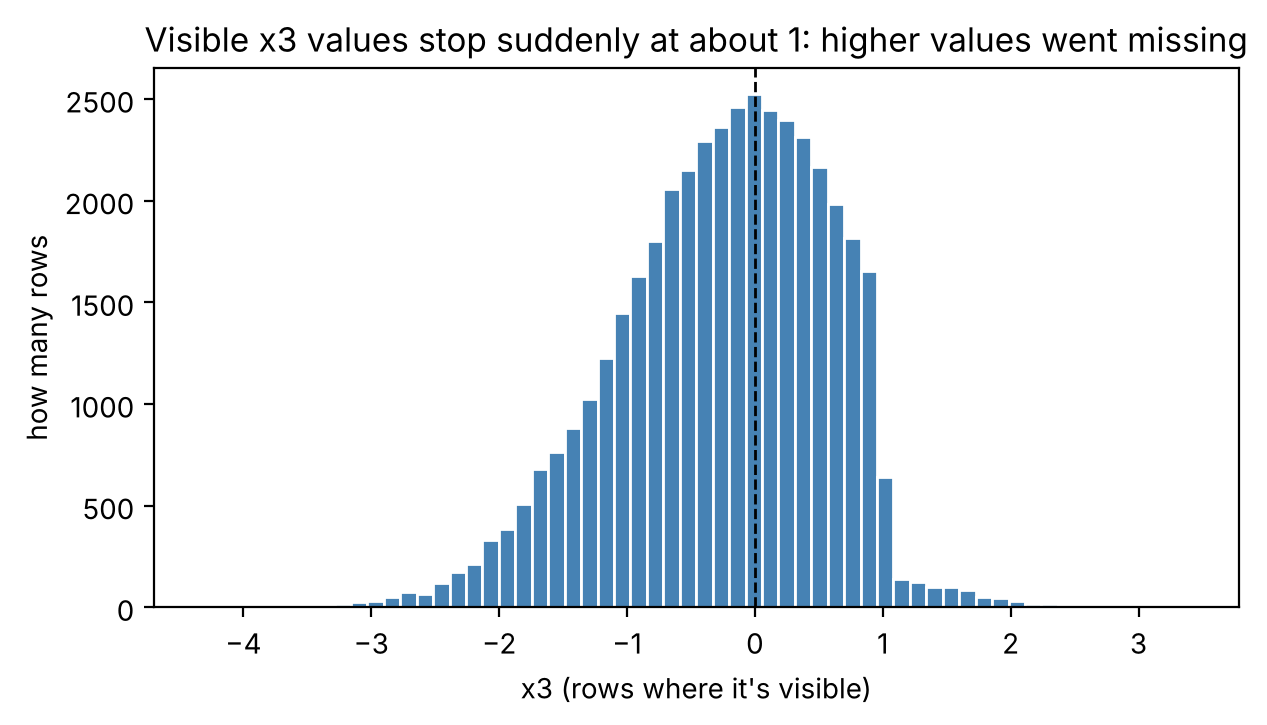

In [6]:
plt.figure(figsize=(7, 3.5))
plt.hist(train["x3"].dropna(), bins=60, color="steelblue", edgecolor="white")
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("x3 (rows where it's visible)"); plt.ylabel("how many rows")
plt.title("Visible x3 values stop suddenly at about 1: higher values went missing")
plt.show()

### Step 2.3: Sector and exchange

**What this cell does:** draws the average price for each sector and each exchange.

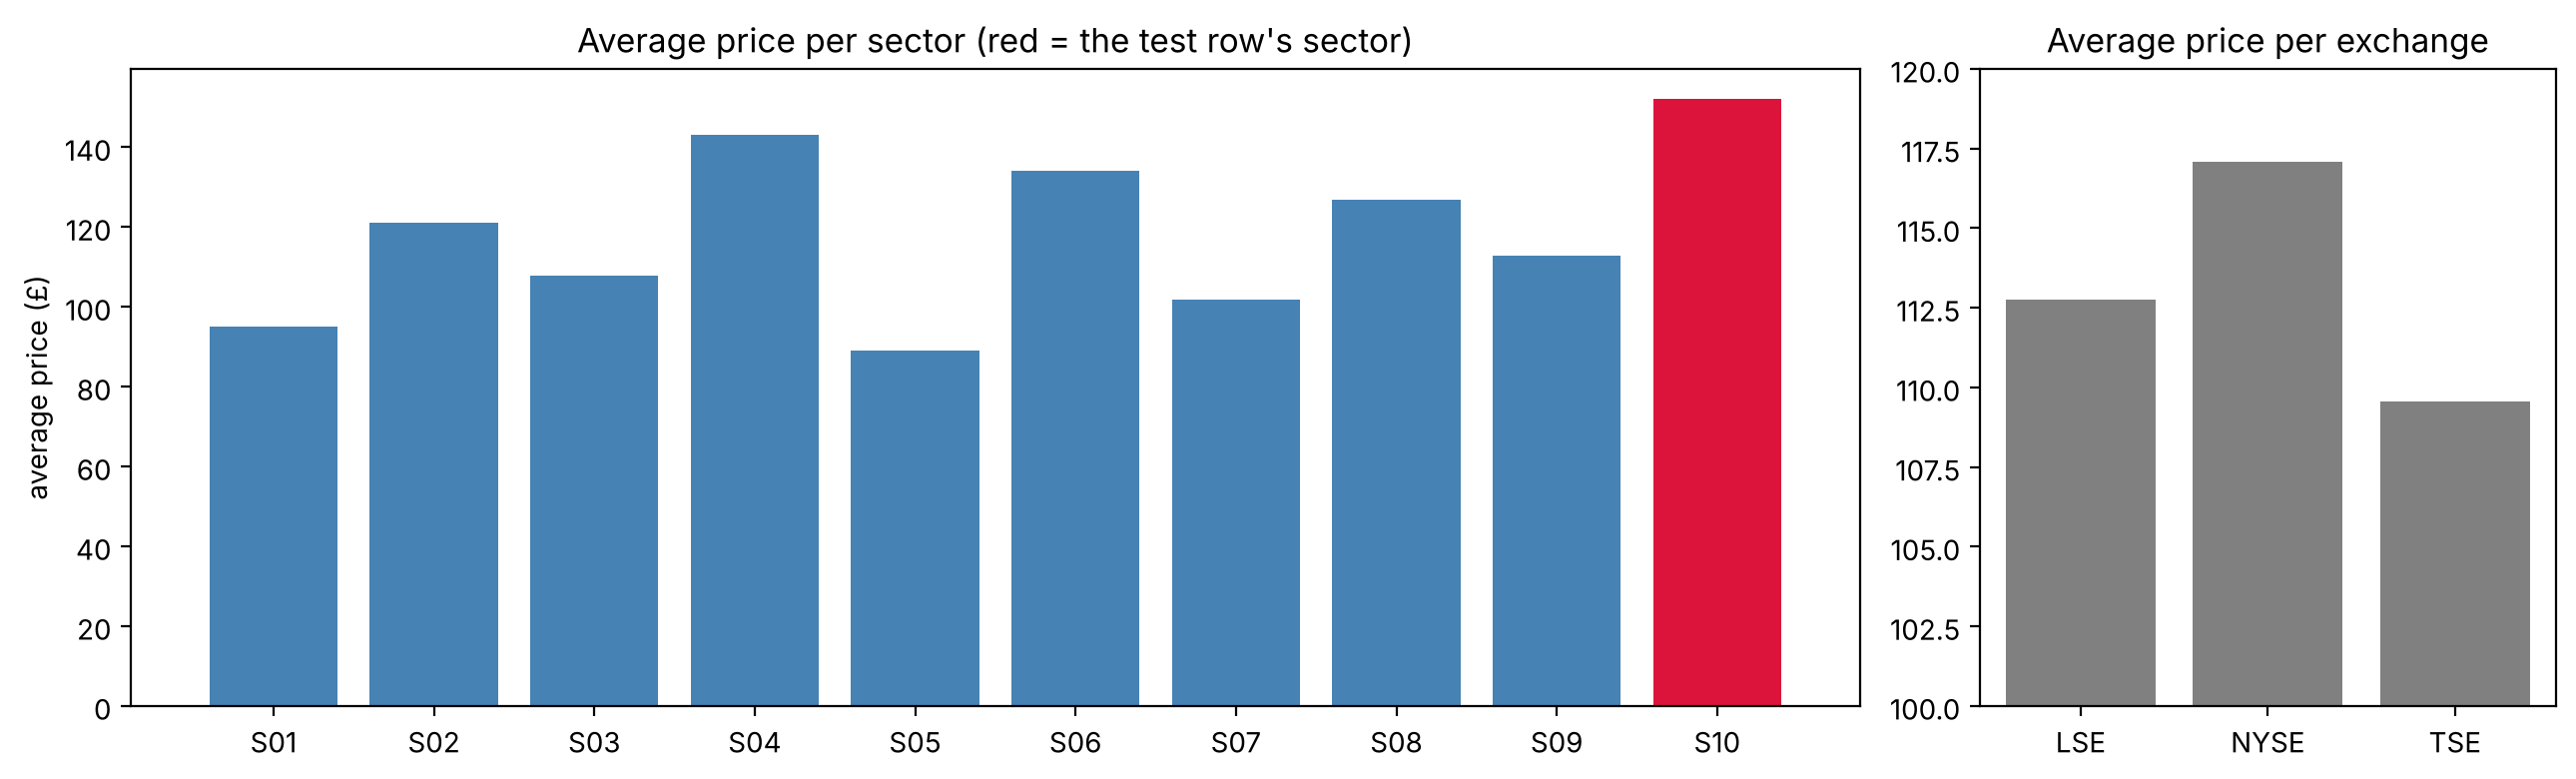

sector
S01     94.97
S02    121.15
S03    107.80
S04    143.12
S05     88.94
S06    134.06
S07    101.81
S08    126.73
S09    112.84
S10    152.01


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})

by_sector = train.groupby("sector")["price"].mean()
axes[0].bar(by_sector.index, by_sector.values, color=["crimson" if s == "S10" else "steelblue" for s in by_sector.index])
axes[0].set_ylabel("average price (£)"); axes[0].set_title("Average price per sector (red = the test row's sector)")

by_exchange = train.groupby("exchange")["price"].mean()
axes[1].bar(by_exchange.index, by_exchange.values, color="grey")
axes[1].set_ylim(100, 120); axes[1].set_title("Average price per exchange")

plt.tight_layout()
plt.show()
print(by_sector.round(2).to_string())

**How to read the output:** sector matters a lot, with averages from about **£89 (S05)** to **£152 (S10)**. Exchange matters a little: NYSE about £4 above LSE, TSE about £3 below.

### Step 2.4: How do the number clues move the price?

Sector and exchange have big effects, so we **remove them first**. Otherwise they'd hide the smaller effects. Then we use the same "slices" idea as stock 3 (10 slices per clue, with the average in each).

**What this cell does:** subtracts each row's sector average and exchange effect from its price, then draws the average of what's left for 10 slices of each clue.

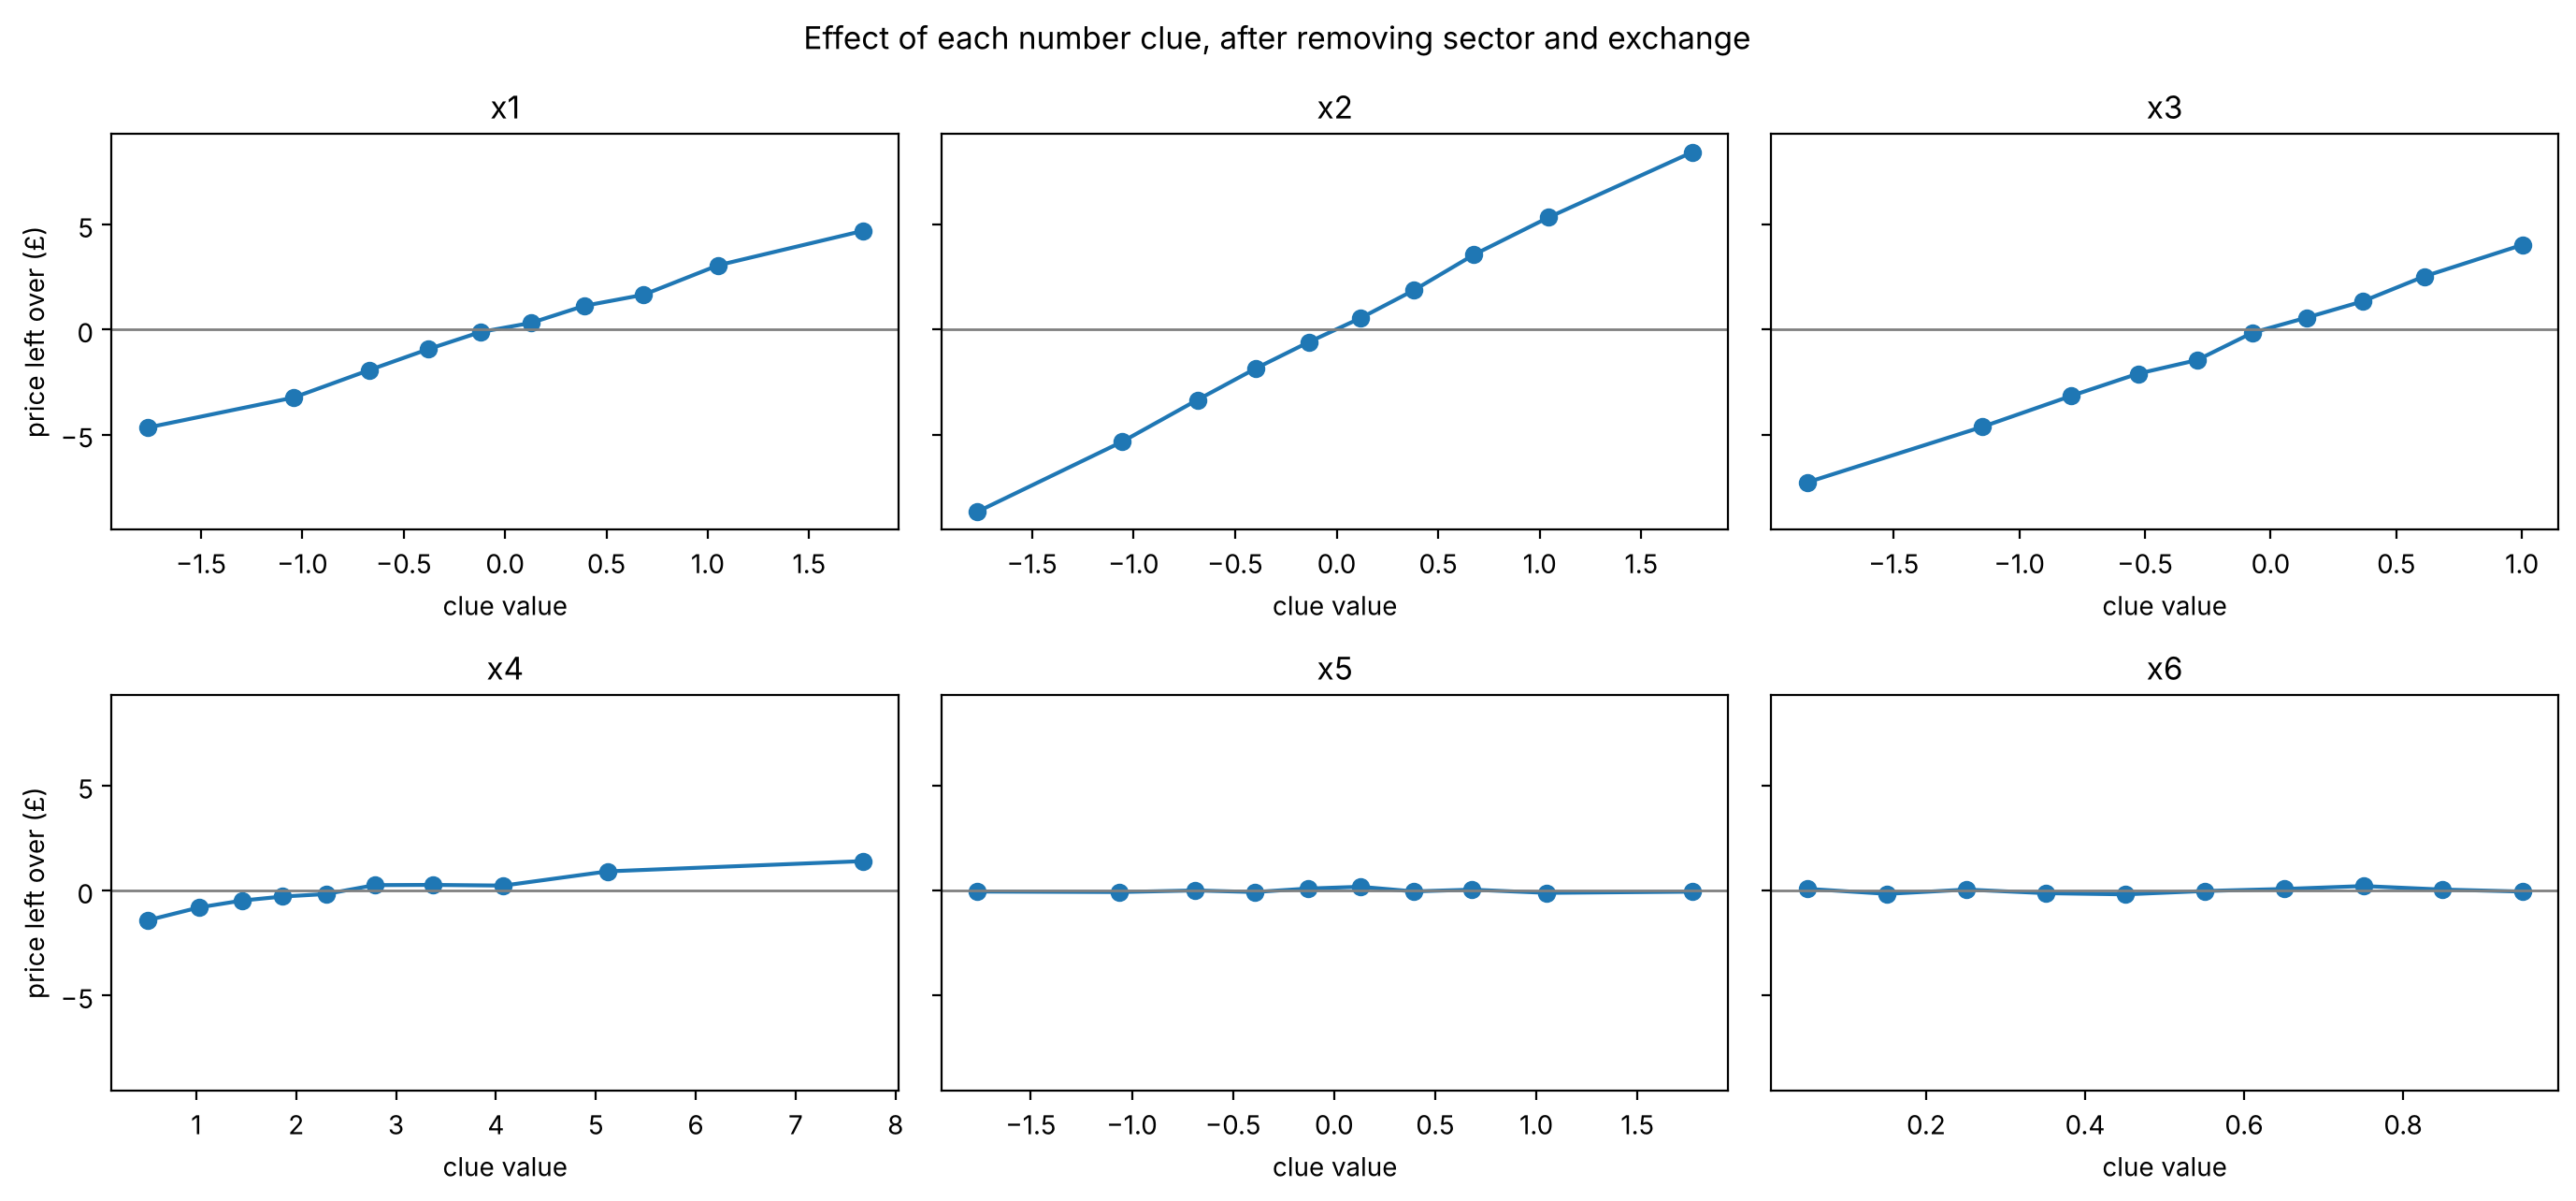

In [8]:
sector_average = train.groupby("sector")["price"].transform("mean")                          # each row's sector average
exchange_shift = train.groupby("exchange")["price"].transform("mean") - train["price"].mean()  # each row's exchange effect
adjusted = train["price"] - sector_average - exchange_shift                                    # price with both removed

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharey=True)
for ax, clue in zip(axes.ravel(), numbers):
    visible = train[clue].notna()
    slices = pd.qcut(train.loc[visible, clue], 10)                       # 10 slices with equal numbers of rows
    clue_mid = train.loc[visible, clue].groupby(slices, observed=True).mean()
    avg_left = adjusted[visible].groupby(slices, observed=True).mean()
    ax.plot(clue_mid.values, avg_left.values, marker="o")
    ax.axhline(0, color="grey", linewidth=1)
    ax.set_title(clue); ax.set_xlabel("clue value")
axes[0, 0].set_ylabel("price left over (£)"); axes[1, 0].set_ylabel("price left over (£)")
fig.suptitle("Effect of each number clue, after removing sector and exchange")
plt.tight_layout()
plt.show()

**How to read the output**

| Clue | Shape |
|---|---|
| x1 | Straight line up (but see Step 2.5) |
| x2 | Straight line up, steep |
| x3 | Straight line up |
| x4 | Small effect, gently up |
| x5, x6 | **Flat**: no effect |

### Step 2.5: Does every sector follow the same formula?

**What this cell does:** fits a separate straight-line model **for each sector** and shows the weights side by side. x3 is filled with its average plus a flag, as decided in Step 2.2.

In [9]:
def simple_clues(data):
    # number clues, with x3 filled with its average plus a "missing" flag, and exchange as 0/1 columns
    return pd.DataFrame({
        "x1": data["x1"], "x2": data["x2"],
        "x3 (filled)": data["x3"].fillna(x3_average),
        "x3 missing": data["x3"].isna().astype(int),
        "x4": data["x4"], "x5": data["x5"], "x6": data["x6"],
        "NYSE": (data["exchange"] == "NYSE").astype(int),
        "TSE": (data["exchange"] == "TSE").astype(int),
    })

sector_models, weight_table = {}, []
for sector, part in train.groupby("sector"):
    model = LinearRegression().fit(simple_clues(part), part["price"])
    sector_models[sector] = model
    weight_table.append({"sector": sector, "rows": len(part), **dict(zip(simple_clues(part).columns, model.coef_))})

pd.DataFrame(weight_table).set_index("sector").round(2)

,rows,x1,x2,x3 (filled),x3 missing,x4,x5,x6,NYSE,TSE
sector,,,,,,,,,,
S01,8063,5.97,5.01,4.00,6.03,0.34,-0.02,-0.06,4.60,-2.89
S02,7093,-3.90,4.99,4.02,6.16,0.33,0.05,-0.07,4.52,-3.06
S03,6455,9.10,4.98,3.95,6.02,0.30,-0.01,0.22,4.42,-3.11
S04,6030,2.01,4.96,4.00,6.18,0.38,-0.01,0.11,4.42,-2.80
S05,5512,11.02,4.94,3.98,6.04,0.34,0.04,0.10,4.49,-2.98
S06,5010,-7.11,5.12,4.07,6.09,0.31,0.10,-0.01,4.36,-3.14
S07,4459,2.92,4.95,3.99,5.90,0.32,-0.03,0.05,4.52,-3.18
S08,3990,4.95,4.99,4.04,6.17,0.28,0.06,0.24,4.36,-2.94
S09,3350,-1.96,4.89,3.96,6.06,0.36,-0.04,-0.42,4.76,-3.23


**How to read the output:** read the table **column by column**.

* **x2 ≈ 5, x3 ≈ 4, x4 ≈ 0.3, NYSE ≈ +4.5, TSE ≈ −3** in every sector. Those effects are **the same everywhere**.
* **x5 and x6 ≈ 0** everywhere. They're useless.
* **x1 is completely different in each sector**: +11 in S05, −7 in S06, and **−13.7 in S10**.

So the right formula is: **each sector has its own starting price and its own x1 weight, and everything else is shared.**

In Step 2.4, x1 looked like a gentle line going up. That was the **average** of all the sectors' x1 lines. For S10, x1 actually pushes the price **down**, and hard. The test row has x1 = 1.85, so this matters a lot.

(S10's x3 weight of 2.5 is lower than the others. With only 38 rows, that's most likely noise, and it hardly matters for our test row anyway, because its x3 is missing. Step 5.2 confirms the price doesn't change.)

### Step 2.6: See it: x1 in a big sector vs in S10

**What this cell does:** for S01 (8,063 rows) and S10 (38 rows), removes the effect of everything except x1 from the price, then plots the result against x1, with each sector's line. The dashed line is the test row's x1.

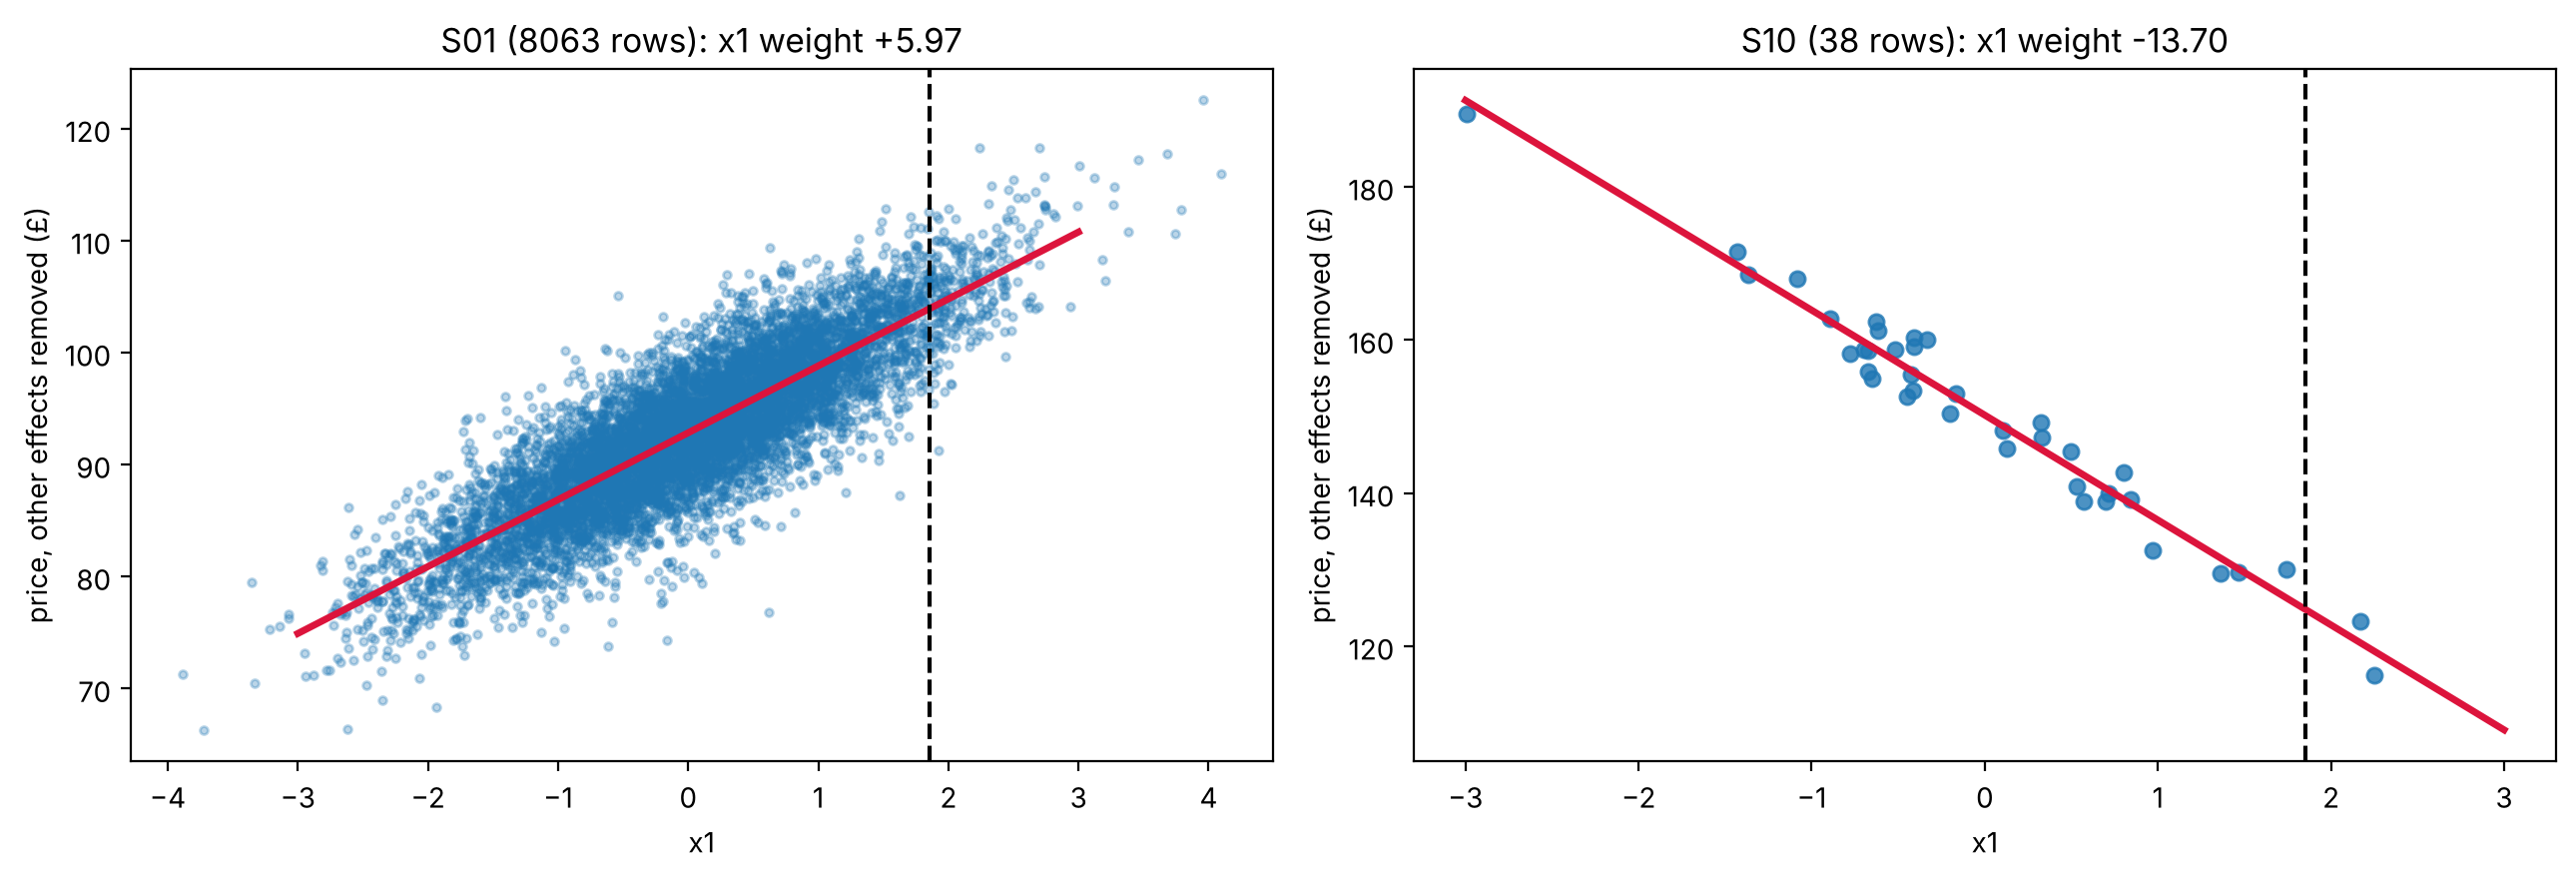

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, sector in zip(axes, ["S01", "S10"]):
    part = train[train["sector"] == sector]
    model = sector_models[sector]
    clues_part = simple_clues(part)
    w_x1 = model.coef_[0]                                            # this sector's x1 weight
    other_effects = model.predict(clues_part) - model.intercept_ - w_x1 * part["x1"]
    ax.scatter(part["x1"], part["price"] - other_effects, s=8 if sector == "S01" else 30, alpha=0.3 if sector == "S01" else 0.8)
    xs = np.linspace(-3, 3, 50)
    ax.plot(xs, model.intercept_ + w_x1 * xs, color="crimson", linewidth=2.5)
    ax.axvline(test_row["x1"], color="black", linestyle="--")
    ax.set_title(f"{sector} ({len(part)} rows): x1 weight {w_x1:+.2f}")
    ax.set_xlabel("x1"); ax.set_ylabel("price, other effects removed (£)")
plt.tight_layout()
plt.show()

**How to read the output:** in S01 the price goes **up** with x1. In S10 it goes **down**, steeply. Even with only 38 dots, S10's dots clearly follow a downward line. The test row's x1 (1.85) is inside the range of S10's own x1 values.

> **✅ Checkpoint.** Three traps:
> 1. **x3 is missing**, and a missing x3 means "probably high". Fix: fill it **and add a flag**.
> 2. **The test row's sector, S10, is rare** (38 rows), and its x1 works in the opposite direction from most sectors. Fix: let **each sector have its own x1 weight**.
> 3. **Text clues** (sector, exchange) must be turned into numbers.

---
# Part 3: Test 9 models

### Step 3.1: The fair-test setup

**What this cell does:** splits the data into clues (`X`) and prices (`y`), sets up 5-fold cross-validation, and marks two groups of rows that need checking separately: **S10 rows** and **missing-x3 rows**.

In [11]:
X = train[clues]
y = train["price"]
X_test = test[clues]

cv = KFold(n_splits=5, shuffle=True, random_state=0)    # 5 fair tests

is_s10 = (train["sector"] == "S10").values               # True for the 38 S10 rows
is_x3_missing = train["x3"].isna().values                # True for the 8,506 missing-x3 rows

### Step 3.2: Preparing the clues for the models

Models only understand numbers, so every model gets the same preparation:

| Clues | Preparation | Example |
|---|---|---|
| `sector`, `exchange` | **One-hot**: one 0/1 column per label | S10 becomes `sector_S10 = 1`, all other sector columns 0. (S01 and LSE are the "starting point", so they have no column.) |
| `x3` | **Fill + flag**: empty cells get the average (−0.26), plus a column "x3 missing" (0/1) | The test row becomes x3 = −0.26, x3 missing = 1 |
| `x1`, `x2`, `x4`, `x5`, `x6` | Kept as they are (scaled for KNN and the neural network) | |

One model also gets **x1 per sector**: 10 copies of x1, one per sector, each set to 0 outside its own sector. That lets a straight-line model learn a different x1 weight in every sector, which is what Step 2.5 showed.

**What this cell does:** writes these preparation steps as reusable building blocks, then shows the test row after preparation.

In [12]:
sectors = sorted(train["sector"].unique())

def add_x1_per_sector(data):
    # add 10 columns x1_S01 ... x1_S10: the row's x1 in its own sector's column, 0 in the others
    data = data.copy()
    for s in sectors:
        data[f"x1_{s}"] = data["x1"] * (data["sector"] == s)
    return data

def prepare(flag=True, scale=False, x1_per_sector=False):
    # the preparation steps every model uses (options switch parts on or off)
    number_cols = ["x2", "x4", "x5", "x6"] + ([f"x1_{s}" for s in sectors] if x1_per_sector else ["x1"])
    columns = ColumnTransformer([
        ("text", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["sector", "exchange"]),
        ("x3", SimpleImputer(strategy="mean", add_indicator=flag), ["x3"]),     # fill x3 (+ flag if switched on)
        ("numbers", "passthrough", number_cols),
    ])
    steps = [("x1_per_sector", FunctionTransformer(add_x1_per_sector))] if x1_per_sector else []
    steps.append(("prep", columns))
    if scale:
        steps.append(("scale", StandardScaler()))            # KNN and neural networks need every column on the same scale
    return steps

example = Pipeline(prepare()).fit(X)                          # basic preparation, learned from the training rows
pd.DataFrame(example.transform(X_test), columns=example.named_steps["prep"].get_feature_names_out()).round(3)

,text__sector_S02,text__sector_S03,text__sector_S04,text__sector_S05,text__sector_S06,text__sector_S07,text__sector_S08,text__sector_S09,text__sector_S10,text__exchange_NYSE,text__exchange_TSE,x3__x3,x3__missingindicator_x3,numbers__x2,numbers__x4,numbers__x5,numbers__x6,numbers__x1
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,-0.256,1.0,0.266,2.4,-0.346,0.611,1.855


**How to read the output:** the test row is now all numbers. `text__sector_S10 = 1` and `text__exchange_NYSE = 1` mark its sector and exchange. `x3__x3 = −0.256` is the filled value, and `x3__missingindicator_x3 = 1` is the flag saying it was missing.

### Step 3.3: Three scores per model

Overall CV RMSE averages over all 50,000 rows. **S10 is only 38 of them (0.08%)**, so a model could be terrible on S10 and still score well overall. So we also measure:

1. **Error on S10 rows**: the model's typical error on the 38 S10 rows
2. **Error on missing-x3 rows**: its typical error on the 8,506 rows with x3 missing

Both are measured fairly: each row is predicted by a model that **didn't see that row** in training (`cross_val_predict`).

### Step 3.4: The 9 models

| Family | Model | How it works, in one line |
|---|---|---|
| Straight line | Linear (x3 filled with average) | The naive version: fills x3 with the average, no flag |
| Straight line | Linear + missing flag | Adds the flag |
| Straight line | **Linear + flag + x1 per sector** | Adds a separate x1 weight for every sector (Step 2.5) |
| Distance | KNN | Averages the prices of the most similar rows |
| Trees | Random forest | Many decision trees, averaged |
| Trees | HistGB, XGBoost, LightGBM | Trees built one after another, each fixing the last one's errors |
| Neural network | MLP | Layers of "neurons" that can learn any shape, including different x1 lines per sector |

The tree models and the neural network could, in principle, learn a different x1 effect per sector by themselves. The question is whether **38 rows are enough** for them to do it.

**What this cell does:** lists each model with the settings to try.

In [13]:
grid_models = {
    "Linear (x3 filled with average)": (
        Pipeline(prepare(flag=False) + [("model", LinearRegression())]), {}),
    "Linear + missing flag": (
        Pipeline(prepare() + [("model", LinearRegression())]), {}),
    "Linear + flag + x1 per sector": (
        Pipeline(prepare(x1_per_sector=True) + [("model", LinearRegression())]), {}),
    "KNN": (
        Pipeline(prepare(scale=True) + [("model", KNeighborsRegressor())]),
        {"model__n_neighbors": [10, 30]}),                       # how many similar rows to average
    "Random forest": (
        Pipeline(prepare() + [("model", RandomForestRegressor(n_estimators=100, max_features=0.5, random_state=0, n_jobs=1))]),
        {"model__min_samples_leaf": [5, 20]}),                   # fewest rows at the end of a branch
    "HistGB": (
        Pipeline(prepare() + [("model", HistGradientBoostingRegressor(max_iter=500, random_state=0))]),
        {"model__max_depth": [3, None],                          # tree size (None = no limit)
         "model__learning_rate": [0.05, 0.1]}),                  # how big a correction each new tree makes
    "Neural network (MLP)": (
        Pipeline(prepare(scale=True) + [("model", MLPRegressor(max_iter=300, early_stopping=True, random_state=0))]),
        {"model__hidden_layer_sizes": [(64, 64), (128, 64)],     # neurons in each layer
         "model__alpha": [0.0001, 0.01]}),                       # penalty that keeps the weights small
}

random_models = {
    "XGBoost": (
        Pipeline(prepare() + [("model", XGBRegressor(random_state=0, n_jobs=1))]),
        {"model__n_estimators": [300, 600, 1000],      # how many trees
         "model__learning_rate": [0.03, 0.05, 0.1],    # how big a correction each new tree makes
         "model__max_depth": [3, 4, 6],                # how big each tree can grow
         "model__min_child_weight": [1, 10],           # fewest rows at the end of a branch
         "model__subsample": [0.8, 1.0],               # share of rows each tree sees
         "model__colsample_bytree": [0.5, 0.8, 1.0],   # share of clues each tree sees
         "model__reg_lambda": [1, 10]}),               # penalty that keeps the effects small
    "LightGBM": (
        Pipeline(prepare() + [("model", LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1))]),
        {"model__n_estimators": [300, 600, 1000],
         "model__learning_rate": [0.03, 0.05, 0.1],
         "model__num_leaves": [7, 15, 31],
         "model__min_child_samples": [5, 20, 50],      # small values let trees look at rare groups like S10
         "model__subsample": [0.8, 1.0],
         "model__colsample_bytree": [0.5, 0.8, 1.0],
         "model__reg_lambda": [0, 10]}),
}
print("Models ready:", list(grid_models) + list(random_models))

Models ready: ['Linear (x3 filled with average)', 'Linear + missing flag', 'Linear + flag + x1 per sector', 'KNN', 'Random forest', 'HistGB', 'Neural network (MLP)', 'XGBoost', 'LightGBM']


### Step 3.5: Run the contest

**What this cell does:** for each model, it
1. tries the settings with 5-fold cross-validation and keeps the best (`GridSearchCV`, or `RandomizedSearchCV` with 10 random combinations for XGBoost and LightGBM)
2. makes fair predictions for every training row (`cross_val_predict`) to score S10 rows and missing-x3 rows
3. prices the test row

It takes several minutes. You'll see "… done" after each model.

In [14]:
def rmse(errors):
    return float(np.sqrt(np.mean(errors ** 2)))

results, searches = [], {}

def record(name, search):
    # score one finished search overall, on S10 rows, on missing-x3 rows, and price the test row
    searches[name] = search
    fair_pred = cross_val_predict(search.best_estimator_, X, y, cv=cv, n_jobs=-1)   # each row predicted by a model that never saw it
    errors = y.values - fair_pred
    results.append({
        "model": name,
        "CV RMSE, all rows (£)": round(-search.best_score_, 2),
        "error on S10 rows (£)": round(rmse(errors[is_s10]), 2),
        "error on missing-x3 rows (£)": round(rmse(errors[is_x3_missing]), 2),
        "test price (£)": round(float(search.predict(X_test)[0]), 2),
    })
    print(f"{name} done")

for name, (pipe, settings) in grid_models.items():
    search = GridSearchCV(pipe, settings, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

for name, (pipe, settings) in random_models.items():
    search = RandomizedSearchCV(pipe, settings, n_iter=10, cv=cv, random_state=0,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

results = pd.DataFrame(results).sort_values("CV RMSE, all rows (£)").reset_index(drop=True)
results

Linear (x3 filled with average) done


Linear + missing flag done


Linear + flag + x1 per sector done


KNN done


Random forest done


HistGB done


Neural network (MLP) done


XGBoost done


LightGBM done


,model,"CV RMSE, all rows (£)",error on S10 rows (£),error on missing-x3 rows (£),test price (£)
0,Linear + flag + x1 per sector,3.76,3.26,4.81,137.68
1,Neural network (MLP),3.85,11.81,4.94,164.52
2,LightGBM,3.88,12.62,4.91,150.57
3,HistGB,3.95,21.13,4.95,159.30
4,XGBoost,3.97,15.75,5.01,135.32
5,Random forest,4.36,43.71,5.32,117.73
6,KNN,4.76,13.19,5.90,150.82
7,Linear + missing flag,6.88,17.90,7.54,168.21
8,Linear (x3 filled with average),7.24,18.23,9.07,162.94


**How to read the output**

| Column | Meaning |
|---|---|
| CV RMSE, all rows | The usual score, averaged over all 50,000 rows |
| error on S10 rows | How wrong the model is on the 38 S10 rows. **This is the one that matters for our test row.** |
| error on missing-x3 rows | How wrong it is when x3 is missing, like in our test row |
| test price | The model's price for the test row |

### Step 3.6: The scores side by side

**What this cell does:** draws the overall score next to the S10 score, and each model's test price.

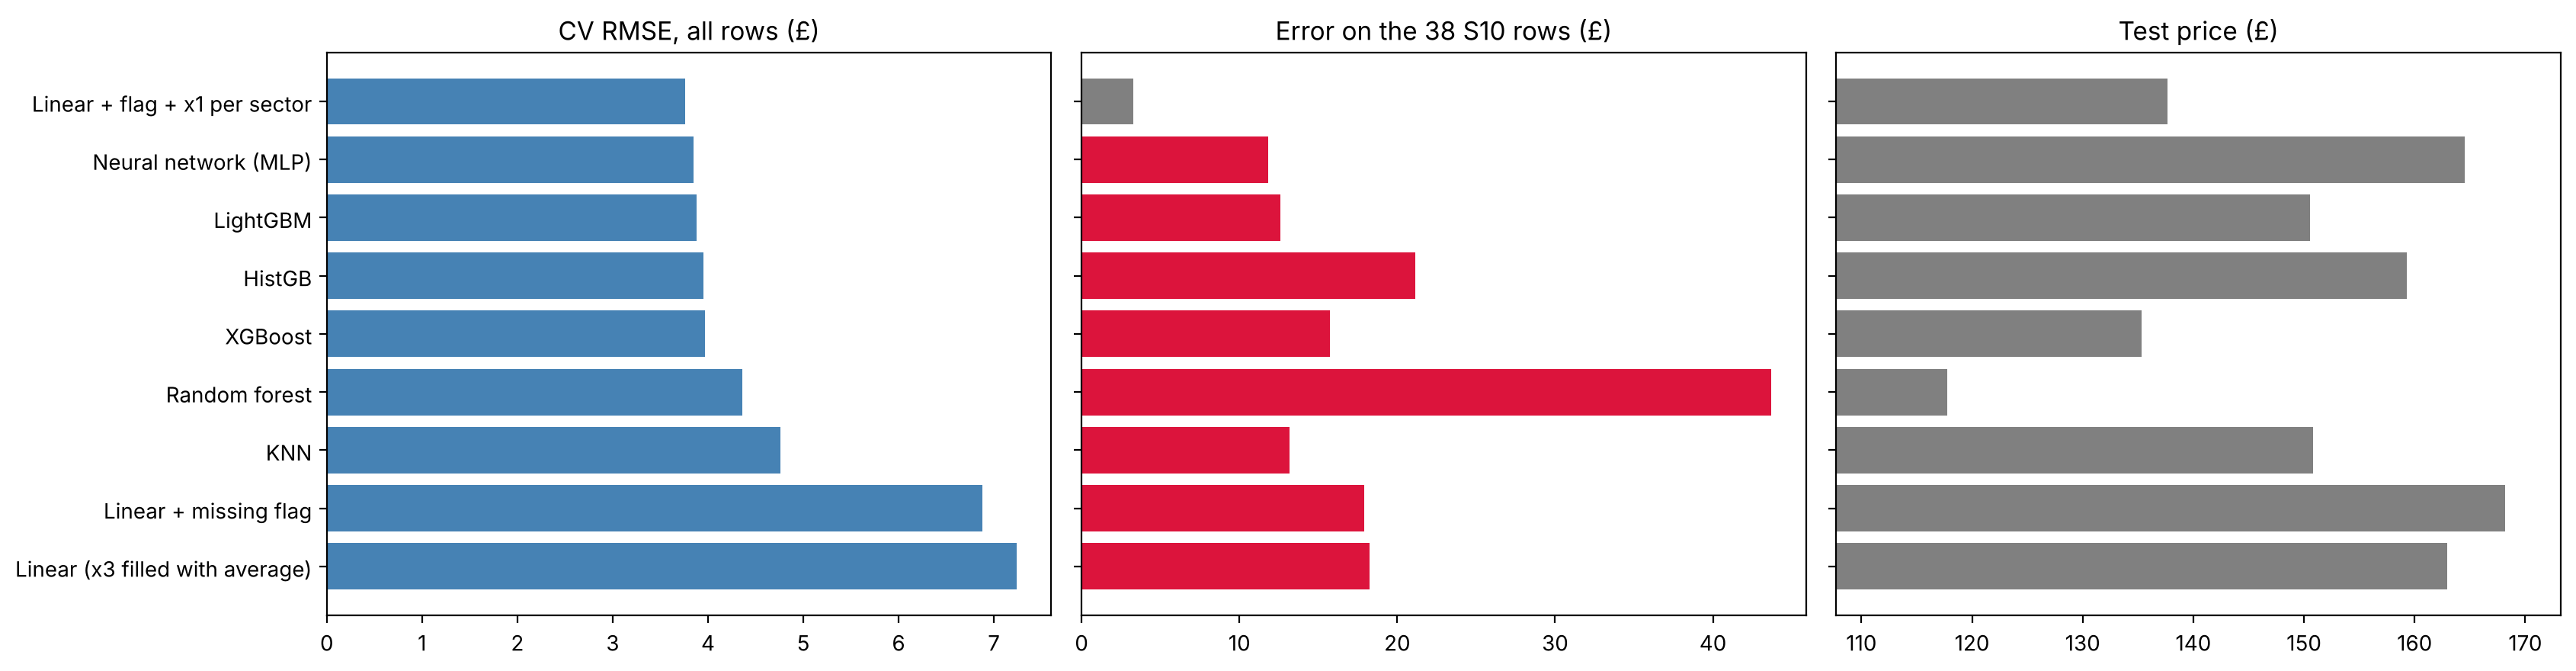

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)

axes[0].barh(results["model"], results["CV RMSE, all rows (£)"], color="steelblue")
axes[0].set_title("CV RMSE, all rows (£)")
axes[0].invert_yaxis()                                      # best overall score at the top

s10 = results["error on S10 rows (£)"]
axes[1].barh(results["model"], s10, color=["crimson" if v > 6 else "grey" for v in s10])
axes[1].set_title("Error on the 38 S10 rows (£)")

axes[2].barh(results["model"], results["test price (£)"], color="grey")
axes[2].set_xlim(results["test price (£)"].min() - 10, results["test price (£)"].max() + 5)
axes[2].set_title("Test price (£)")

plt.tight_layout()
plt.show()

### Step 3.7: Slide x1 for the test row

**What this cell does:** keeps the test row the same but changes x1 from −3 to 3, and asks each model for a price. From Step 2.6, the right answer for S10 is a **steep line going down** (about −£13.70 per unit of x1). The grey area is the range of x1 seen in S10, and the dashed line is the test row's x1.

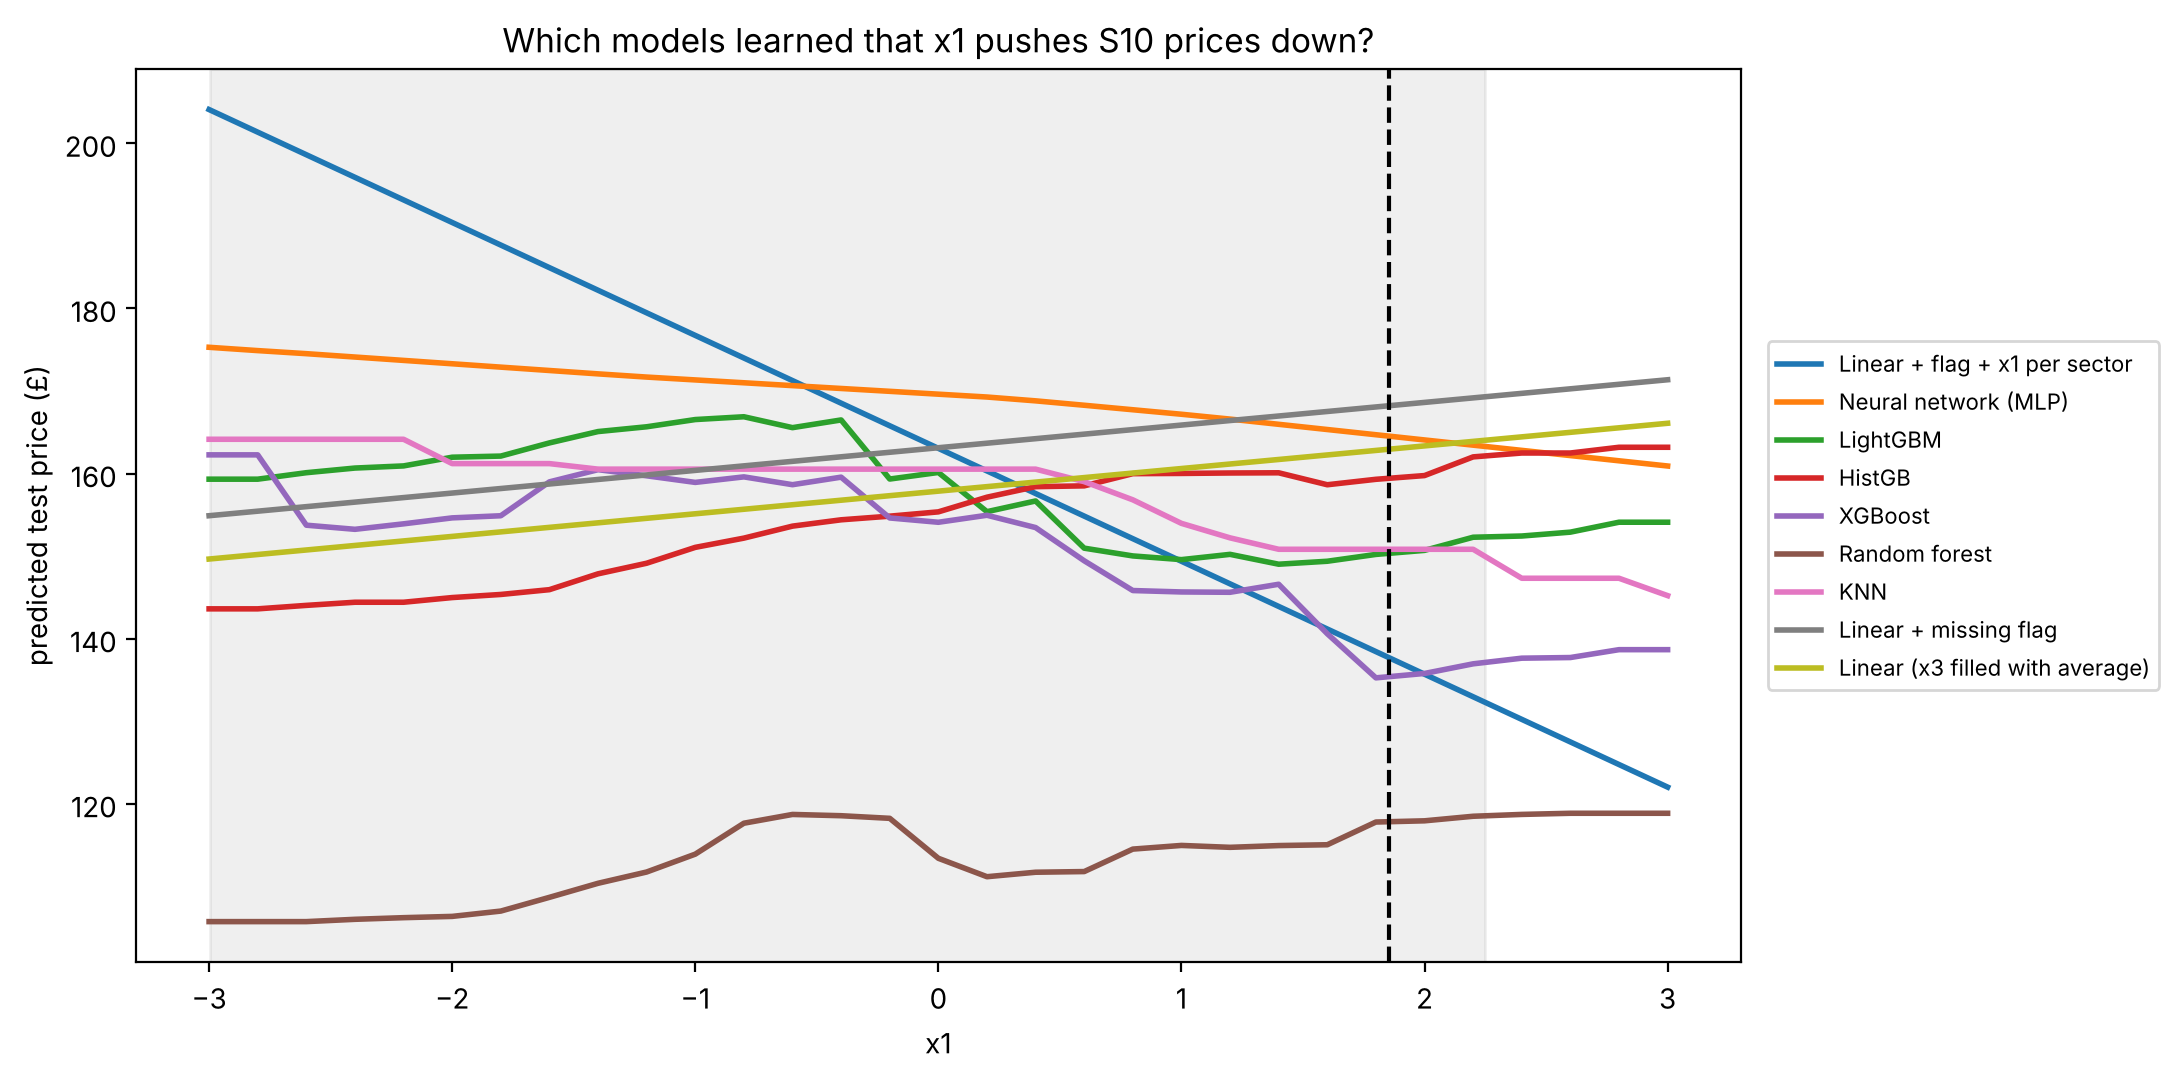

In [16]:
x1_values = np.linspace(-3, 3, 31)
test_copies = pd.concat([X_test] * len(x1_values), ignore_index=True)    # 31 copies of the test row
test_copies["x1"] = x1_values                                            # each copy gets a different x1

s10_x1 = train.loc[is_s10, "x1"]
plt.figure(figsize=(11, 5.5))
for name in results["model"]:
    plt.plot(x1_values, np.ravel(searches[name].predict(test_copies)), label=name, linewidth=2)
plt.axvspan(s10_x1.min(), s10_x1.max(), color="grey", alpha=0.12)
plt.axvline(test_row["x1"], color="black", linestyle="--")
plt.xlabel("x1"); plt.ylabel("predicted test price (£)")
plt.title("Which models learned that x1 pushes S10 prices down?")
plt.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

**How to read Steps 3.5 to 3.7**

* **Linear + flag + x1 per sector** is the best overall (about £3.76), and it's the **only** model that's right on S10 rows (about £3.26). Its line in the slide chart goes steeply down, as S10's data says it should. Test price: **£137.68**.
* **The neural network, LightGBM, HistGB and XGBoost score almost as well overall (£3.85–3.97)**, but they're **£12–21 wrong on S10 rows**. With only 38 S10 rows, they mostly copy the x1 behaviour of the big sectors. In the slide chart, none of their lines follows the steep downward path.
* **XGBoost's test price (£135.32) happens to be close to ours**, but it's £15.75 wrong on S10 rows in general, and its line in the slide chart wanders up and down. That's luck, not skill, so we can't trust it.
* **Random forest** is the worst on S10 (about £44), and its test price (£118) is far too low.
* **The simple linear models** use one x1 weight for all sectors, so they're also about £18 wrong on S10. Without the flag, missing-x3 rows come out about £5 too low, because the average tells the model "x3 is low" (Step 2.2). Their error rises from about £7.5 to £9.1.

**The big lesson:** a model's overall score says nothing about a **rare group**. Our test row is in a rare group, so we must score models **on that group**.

> **✅ Checkpoint.** The only reliable model is **Linear + flag + x1 per sector**. Every flexible model failed on S10.

---
# Part 4: Pick the most reliable model and look inside it

### Step 4.1: The scorecard

| Model | Overall CV RMSE | Error on S10 rows | Handles missing x3? | Easy to explain? |
|---|---|---|---|---|
| **Linear + flag + x1 per sector** | **£3.76, the best** | **£3.26, the only good one** | **Yes (flag)** | **Yes** |
| Neural network, LightGBM, HistGB, XGBoost | £3.85–3.97 | £12–21 | Yes | No |
| Random forest, KNN | £4.36–4.76 | £13–44 | Yes | No |
| Linear + flag (one x1 weight) | £6.88 | £17.90 | Yes | Yes |
| Linear, x3 filled with average | £7.24 | £18.23 | **No** | Yes |

**Winner: Linear + flag + x1 per sector.**

### Step 4.2: Train the final model and look inside

**What this cell does:** trains the winner on all 50,000 rows, prices the test row, and shows the sum step by step. Only clues that aren't 0 for the test row are shown.

In [17]:
final_model = Pipeline(prepare(x1_per_sector=True) + [("model", LinearRegression())])
final_model.fit(X, y)
prediction = float(final_model.predict(X_test)[0])

names = final_model.named_steps["prep"].get_feature_names_out()          # the prepared column names
weights = final_model.named_steps["model"].coef_
start = final_model.named_steps["model"].intercept_
values = final_model[:-1].transform(X_test)[0]                           # the test row after preparation

print(f"start (sector S01, LSE, every clue 0){'':6}{start:8.2f}")
total = start
for name, weight, value in zip(names, weights, values):
    if value != 0:                                                       # skip clues that are 0 for the test row
        total += weight * value
        print(f"+ {weight:7.2f} × {name:28s} ({value:6.3f})  {weight * value:+8.2f}")
print(f"{'= prediction':45}{total:8.2f}")

start (sector S01, LSE, every clue 0)         92.86
+   58.53 × text__sector_S10             ( 1.000)    +58.53
+    4.49 × text__exchange_NYSE          ( 1.000)     +4.49
+    4.00 × x3__x3                       (-0.256)     -1.03
+    6.07 × x3__missingindicator_x3      ( 1.000)     +6.07
+    4.99 × numbers__x2                  ( 0.266)     +1.33
+    0.33 × numbers__x4                  ( 2.400)     +0.79
+    0.01 × numbers__x5                  (-0.346)     -0.01
+    0.03 × numbers__x6                  ( 0.611)     +0.02
+  -13.68 × numbers__x1_S10              ( 1.855)    -25.37
= prediction                                   137.68


**How to read the output**

* **start ≈ £93**: the price for sector S01 on the LSE with every clue at 0.
* **sector_S10 ≈ +£58.5**: S10 is the most expensive sector.
* **exchange_NYSE ≈ +£4.5**
* **x1_S10 ≈ −13.7 × 1.85 ≈ −£25.4**: the big one. A model with one x1 weight for all sectors would add about +£5 here instead, which is about **£30** of difference.
* **x3 and the missing flag:** x3 is filled with −0.26 (worth about −£1), and the flag adds about +£6. So **a missing x3 is worth about +£5 overall**, just as Step 2.2 suggested.
* x2, x4, x5 and x6 add the rest. x5 and x6 add almost nothing.

**Prediction: £137.68.**

### Step 4.3: Predicted vs actual

**What this cell does:** gets fair predictions for every training row, then plots predicted against actual for 3,000 random rows (blue) and all 38 S10 rows (red). A perfect model would put every dot on the diagonal.

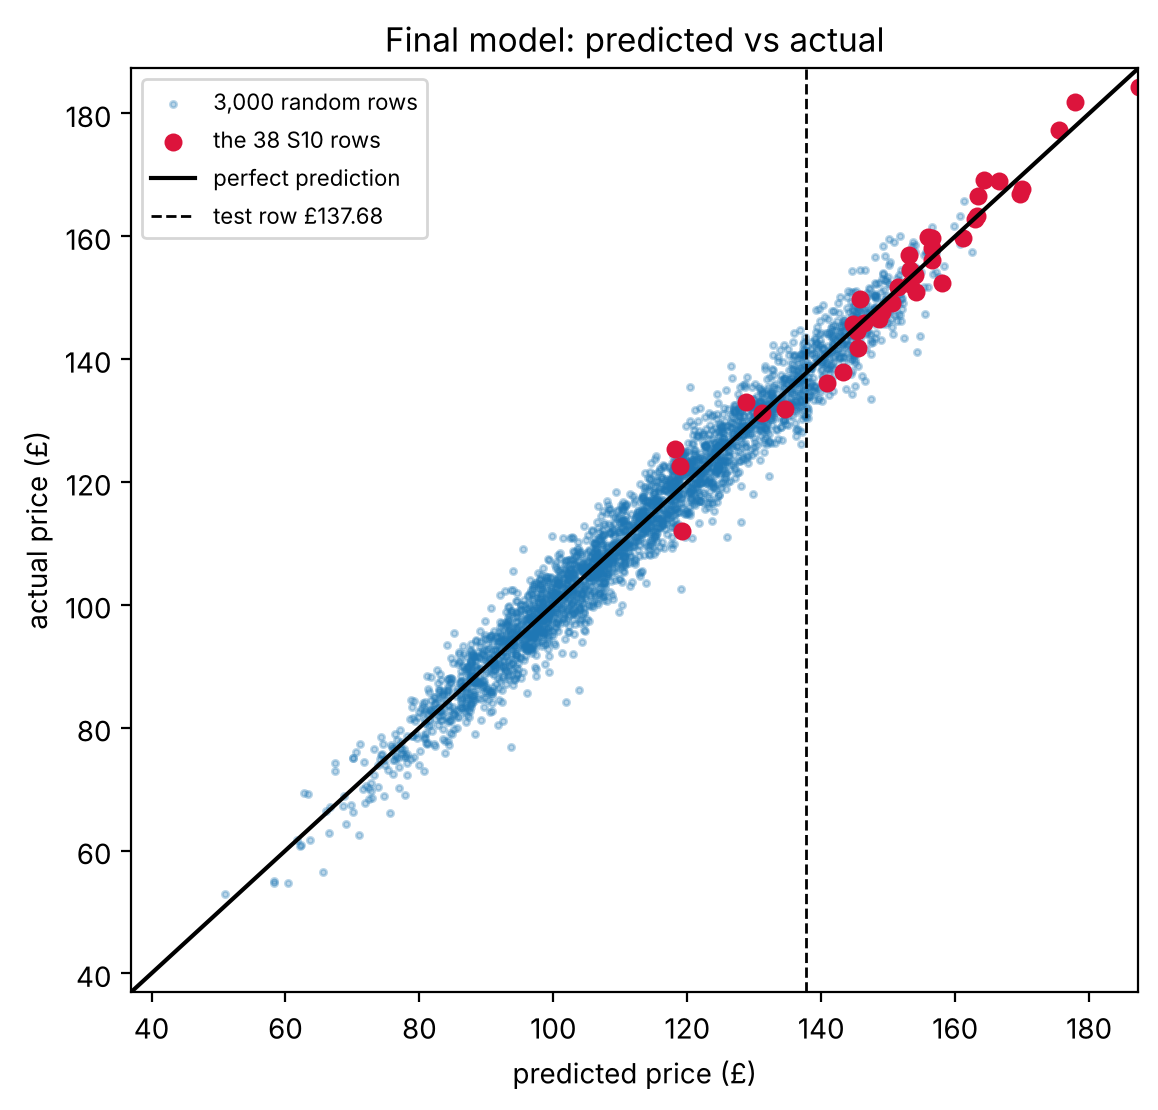

In [18]:
fair_pred = cross_val_predict(final_model, X, y, cv=cv)          # each row predicted by a model that never saw it
errors = y - fair_pred
sample = train.sample(3000, random_state=0).index

plt.figure(figsize=(6.5, 6))
plt.scatter(fair_pred[sample], y[sample], s=5, alpha=0.3, label="3,000 random rows")
plt.scatter(fair_pred[is_s10], y[is_s10], s=30, color="crimson", label="the 38 S10 rows")
lims = [y.min() - 3, y.max() + 3]
plt.plot(lims, lims, color="black", linewidth=1.5, label="perfect prediction")
plt.axvline(prediction, color="black", linestyle="--", linewidth=1, label=f"test row £{prediction:.2f}")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("predicted price (£)"); plt.ylabel("actual price (£)")
plt.title("Final model: predicted vs actual")
plt.legend(loc="upper left", fontsize=8)
plt.show()

**How to read the output:** the dots sit tightly around the diagonal, **including the red S10 dots**. The model works for the rare sector too.

### Step 4.4: How big are the errors when x3 is missing?

**What this cell does:** compares the error size for rows with x3 visible against rows with x3 missing, and counts how many errors fall within ±£5 and ±£10.

x3 visible : error std £3.51   within ±£5: 84.7%   within ±£10: 99.6%
x3 missing : error std £4.81   within ±£5: 72.6%   within ±£10: 95.5%

Missing-x3 rows, middle 95% of errors: -10.91 to +8.68 (£)


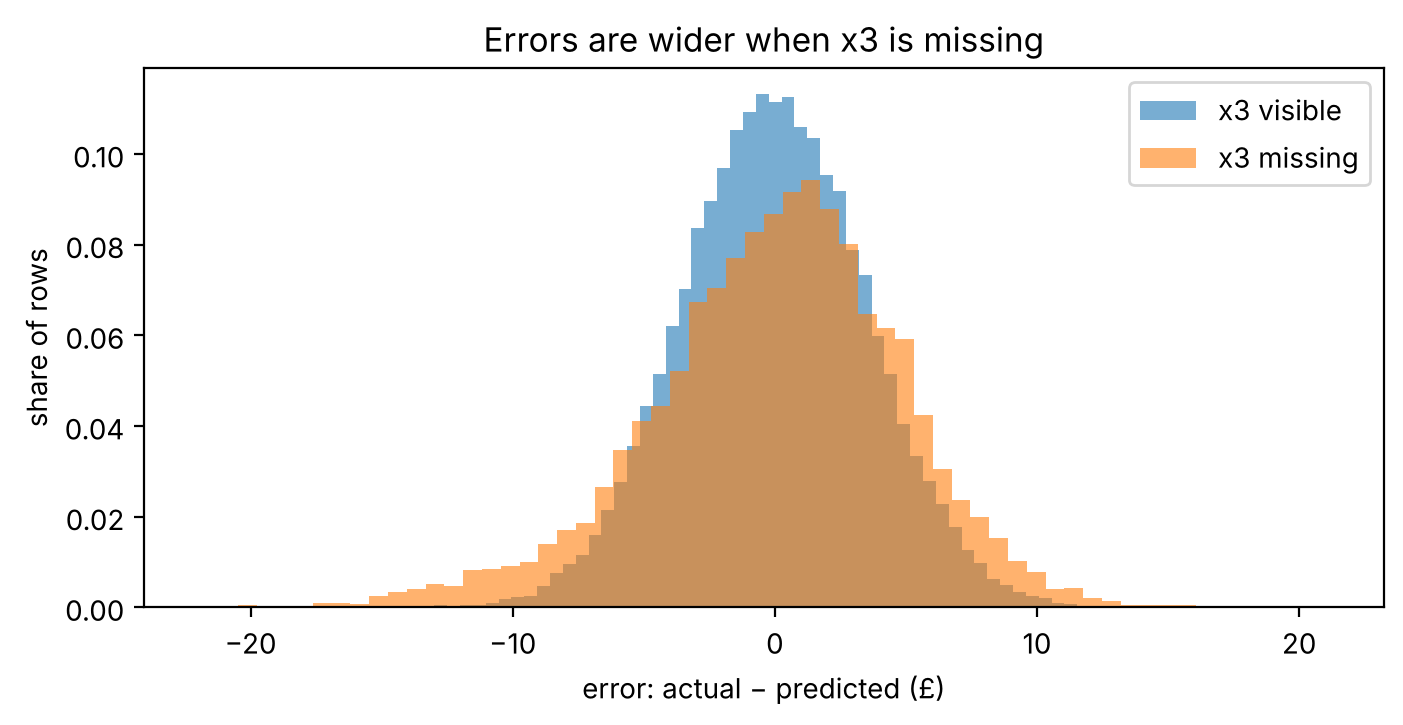

In [19]:
for label, group in [("x3 visible", ~is_x3_missing), ("x3 missing", is_x3_missing)]:
    e = errors[group]
    print(f"{label:11s}: error std £{e.std():.2f}   within ±£5: {(e.abs() <= 5).mean():.1%}   within ±£10: {(e.abs() <= 10).mean():.1%}")

low, high = np.percentile(errors[is_x3_missing], [2.5, 97.5])
print(f"\nMissing-x3 rows, middle 95% of errors: {low:+.2f} to {high:+.2f} (£)")

plt.figure(figsize=(8, 3.5))
plt.hist(errors[~is_x3_missing], bins=60, alpha=0.6, density=True, label="x3 visible")
plt.hist(errors[is_x3_missing], bins=60, alpha=0.6, density=True, label="x3 missing")
plt.xlabel("error: actual − predicted (£)"); plt.ylabel("share of rows")
plt.legend(); plt.title("Errors are wider when x3 is missing")
plt.show()

**How to read the output**

* When x3 is visible, the typical error is about **£3.5**. When it's missing, it's about **£4.8**. That makes sense: the flag tells the model "x3 was probably above 1", but not exactly how high, so there's extra guesswork.
* The orange errors are **lopsided**: the middle 95% runs from about **−£11 to +£9**, with a longer tail on the left. A few rows lost their x3 for other reasons and actually had a low x3, so their real price was well **below** the prediction.

**Our test row has x3 missing, so about £4.8 is the error size that applies to it, with a slightly bigger risk on the downside.**

> **✅ Checkpoint.** Final model: **Linear + flag + x1 per sector**. Prediction **£137.68**, typical error about £4.8 for a row like ours.

---
# Part 5: How sure are we?

### Step 5.1: Model error (bootstrap)

S10's starting price and x1 weight come from only 38 rows, so they might be a bit off. **What this cell does:** retrains the final model 200 times, each time on 50,000 rows picked at random (some twice, some not at all), and prices the test row each time.

In [20]:
rng = np.random.default_rng(0)
boot_prices = []
for b in range(200):
    rows_b = rng.integers(0, len(train), len(train))                 # random rows, some picked twice
    model_b = clone(final_model).fit(X.iloc[rows_b], y.iloc[rows_b])
    boot_prices.append(float(model_b.predict(X_test)[0]))
boot_prices = np.array(boot_prices)

print(f"Average test price over 200 retrains: £{boot_prices.mean():.2f}")
print(f"Spread (std):                         £{boot_prices.std():.2f}")

Average test price over 200 retrains: £137.59
Spread (std):                         £1.25


**How to read the output:** the price moves by about **£1.25**, more than in stock 3 (£0.03), because S10's part of the model is learned from only 38 rows.

### Step 5.2: Cross-check with an S10-only model

**What this cell does:** fits a straight-line model on **only the 38 S10 rows** and prices the test row. If it agrees with our final model, the shared weights (x2, x3, flag, exchange) are safe to use for S10.

In [21]:
s10_rows = train[is_s10]
s10_model = LinearRegression().fit(simple_clues(s10_rows)[["x1", "x2", "x3 (filled)", "x3 missing", "x4", "NYSE", "TSE"]],
                                   s10_rows["price"])
s10_price = float(s10_model.predict(simple_clues(test)[["x1", "x2", "x3 (filled)", "x3 missing", "x4", "NYSE", "TSE"]])[0])
print(f"S10-only model: £{s10_price:.2f}    Final model: £{prediction:.2f}")

S10-only model: £138.09    Final model: £137.68


**How to read the output:** the two agree to within about 50p. The S10-only model uses far fewer rows, so it's less precise, but it confirms the answer.

### Step 5.3: Total uncertainty

**What this cell does:** combines the two sources of uncertainty: model error (Step 5.1) and the error for a missing-x3 row (Step 4.4). Errors from different sources add up like the sides of a right-angled triangle: √(a² + b²).

In [22]:
model_error = boot_prices.std()
row_error = errors[is_x3_missing].std()
total_uncertainty = np.sqrt(model_error ** 2 + row_error ** 2)
print(f"Model error:            £{model_error:.2f}")
print(f"Error for a row like ours (x3 missing): £{row_error:.2f}")
print(f"Total uncertainty:      £{total_uncertainty:.2f}")
print(f"\nLikely range (middle 95%, from Step 4.4): £{prediction + low:.2f} to £{prediction + high:.2f}")

Model error:            £1.25
Error for a row like ours (x3 missing): £4.81
Total uncertainty:      £4.97

Likely range (middle 95%, from Step 4.4): £126.77 to £146.36


**How to read the output:** total uncertainty is about **£5**. So:
* about 68% chance the true price is within **£137.68 ± £5** (about £132.7 to £142.7)
* about 95% chance it's between about **£126.8 and £146.4**. The range stretches further down than up, because of the lopsided errors in Step 4.4.

> **✅ Checkpoint.** Price **£137.68 ± £5**.

---
# Part 6: Make a quote and a trading plan

### Step 6.1: Quote options

**What this cell does:** prints three quotes (**bid = centre − h**, **ask = centre + h**), from tight to wide.

In [23]:
centre = prediction
h_one = round(total_uncertainty, 1)                          # about £5
for h, meaning in [(h_one / 2, "half of the uncertainty: competing to be market maker"),
                   (h_one,     "1 std: true price inside about 68% of the time"),
                   (2 * h_one, "2 std: true price inside about 95% of the time")]:
    print(f"h = £{h:<5.2f}  bid £{centre - h:.2f}   ask £{centre + h:.2f}   ({meaning})")

h = £2.50   bid £135.18   ask £140.18   (half of the uncertainty: competing to be market maker)
h = £5.00   bid £132.68   ask £142.68   (1 std: true price inside about 68% of the time)
h = £10.00  bid £127.68   ask £147.68   (2 std: true price inside about 95% of the time)


### Step 6.2: Should we try to be market maker?

**For:**
* Most teams will get this row badly wrong. Most models that miss the S10 x1 effect land between about **£150 and £168**, which is £13–30 too high. Those teams will **buy** from us at our ask, and on average we profit from their mistake.

**Against:**
* Our own uncertainty (£5) is bigger than on stock 3 (£3), because x3 is missing and S10 is small.
* Most other teams will lean the same way (too high), so if we're market maker, nearly everyone buys from us. If the true price lands high by chance, we lose on all those shares. For example, 5 teams each buy about £100k worth from us (about 700 shares each, 3,500 in total) at £140.18, and the true price comes out at £147.68 (2 std high). We lose about £7.50 × 3,500 ≈ **£26,000**.

**Suggestion:** this is a good stock to **trade against a wrong market maker** rather than to be one. Quote **h = £5 (about £132.7 / £142.7)**. If you want to compete for market maker, use h = £2.50, but expect a big one-sided position.

### Step 6.3: Trading plan (if another team is market maker)

Compare their bid and ask with our centre of **£137.68**, using £5 as the ruler:

| Market maker's prices | What we do | Size |
|---|---|---|
| **Bid above £148** (more than £10 over our centre) | **Sell** | Big |
| Bid between £143 and £148 | Sell | Medium |
| **Ask below £128** (more than £10 under our centre) | **Buy** | Big |
| Ask between £128 and £133 | Buy | Medium |
| Our centre within about £5 of their prices | Little edge | Minimum 10 shares, on the side our centre leans towards |

**Likely scenarios:**
* Market maker used **one x1 weight, LightGBM, HistGB, KNN or a neural network** (mid about £150–168) → **sell big**.
* Market maker used **XGBoost** (mid about £135) → little edge, trade the minimum.
* Market maker used **random forest** (mid about £118) → **buy big**.

---

### Lessons so far

| Stock | Trap | What we did |
|---|---|---|
| 1 | None (warm-up) | Linear regression, quote ±1–2 std |
| 2 | Few rows, extreme test row | Wide quote (±£15), stay a trader |
| 3 | Out-of-range **decoy** clue | Checked it has no effect, removed it, confident quote |
| 5 | **Missing value + rare sector** | Flag for missing x3, a separate x1 weight per sector, scored models on S10 rows only |

> **✅ Final checkpoint.** Stock 5 price **£137.68 ± £5**. Most reliable model: **Linear + flag + x1 per sector**. Models with a good overall score were £12–44 wrong on S10.